In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://www.stat.cmu.edu/~larry/all-of-statistics/=data/faithful.dat"

df = pd.read_csv(
    url,
    sep=r'\s+',
    skiprows=20,
    names=['index', 'eruptions', 'waiting']
)

df = df.drop(columns=['index'])

X = df.to_numpy()

print("Shape:", X.shape)
df.head()

Shape: (273, 2)


,eruptions,waiting
0,waiting,NaN
1,3.600,79.0
2,1.800,54.0
3,3.333,74.0
4,2.283,62.0


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

url = "https://www.stat.cmu.edu/~larry/all-of-statistics/=data/faithful.dat"

df = pd.read_csv(
    url,
    sep=r'\s+',
    skiprows=20,
    names=['index', 'eruptions', 'waiting']
)

df = df[['eruptions', 'waiting']]

# Convert values to numeric and remove non-numeric rows
df = df.apply(pd.to_numeric, errors='coerce')
df = df.dropna().reset_index(drop=True)

X = df.to_numpy(dtype=np.float64)

print("Dataset shape:", X.shape)
print("Data type:", X.dtype)

assert X.shape == (272, 2), "Check dataset parsing"

df.head()

Dataset shape: (272, 2)
Data type: float64


,eruptions,waiting
0,3.600,79.0
1,1.800,54.0
2,3.333,74.0
3,2.283,62.0
4,4.533,85.0


In [6]:
import numpy as np
from scipy.stats import multivariate_normal

np.random.seed(42)

n, d = X.shape
K = 2

# Randomly initialize means
mu = X[np.random.choice(n, K, replace=False)].copy()

# Initialize covariance matrices
sigma = np.array([np.cov(X.T) for _ in range(K)])

# Initialize mixing coefficients
phi = np.ones(K) / K

print("Initial means:\n", mu)
print("\nInitial covariance matrices:\n", sigma)
print("\nInitial mixing coefficients:\n", phi)

Initial means:
 [[ 4.3   73.   ]
 [ 2.317 50.   ]]

Initial covariance matrices:
 [[[  1.30272833  13.97780785]
  [ 13.97780785 184.82331235]]

 [[  1.30272833  13.97780785]
  [ 13.97780785 184.82331235]]]

Initial mixing coefficients:
 [0.5 0.5]


In [7]:
def e_step(X, mu, sigma, phi):
    n = X.shape[0]
    K = len(phi)

    gamma = np.zeros((n, K))

    for k in range(K):
        gamma[:, k] = phi[k] * multivariate_normal.pdf(
            X, mean=mu[k], cov=sigma[k]
        )

    gamma /= gamma.sum(axis=1, keepdims=True)

    return gamma


# Test the E-step
gamma = e_step(X, mu, sigma, phi)

print("Responsibility matrix shape:", gamma.shape)
print("\nFirst 5 responsibilities:\n", gamma[:5])

print("\nVerification:",
      np.allclose(gamma.sum(axis=1), 1))

Responsibility matrix shape: (272, 2)

First 5 responsibilities:
 [[0.7603163  0.2396837 ]
 [0.13392096 0.86607904]
 [0.65529734 0.34470266]
 [0.2704813  0.7295187 ]
 [0.91500133 0.08499867]]

Verification: True


In [8]:
def m_step(X, gamma):
    n, d = X.shape
    K = gamma.shape[1]

    N_k = gamma.sum(axis=0)

    # Update means
    mu = (gamma.T @ X) / N_k[:, None]

    # Update covariance matrices
    sigma = np.zeros((K, d, d))

    for k in range(K):
        diff = X - mu[k]

        sigma[k] = (
            (gamma[:, k, None] * diff).T @ diff
        ) / N_k[k]

        # Prevent singular covariance matrices
        sigma[k] += 1e-6 * np.eye(d)

    # Update mixing coefficients
    phi = N_k / n

    return mu, sigma, phi


# Test the M-step
mu_new, sigma_new, phi_new = m_step(X, gamma)

print("Updated means:\n", mu_new)
print("\nUpdated covariance matrices:\n", sigma_new)
print("\nUpdated mixing coefficients:\n", phi_new)

print("\nVerification:", np.isclose(phi_new.sum(), 1))

Updated means:
 [[ 4.09795303 77.9198357 ]
 [ 2.52316576 59.79475468]]

Updated covariance matrices:
 [[[  0.59572376   5.63410489]
  [  5.63410489  87.68848626]]

 [[  0.88900589   9.5519662 ]
  [  9.5519662  135.39983208]]]

Updated mixing coefficients:
 [0.61253818 0.38746182]

Verification: True


In [9]:
def log_likelihood(X, mu, sigma, phi):
    likelihood = np.zeros(X.shape[0])

    for k in range(len(phi)):
        likelihood += phi[k] * multivariate_normal.pdf(
            X, mean=mu[k], cov=sigma[k]
        )

    return np.sum(np.log(likelihood))


# Test log-likelihood before and after the M-step
ll_initial = log_likelihood(X, mu, sigma, phi)

ll_updated = log_likelihood(
    X, mu_new, sigma_new, phi_new
)

print("Initial log-likelihood:", ll_initial)
print("Updated log-likelihood:", ll_updated)
print("Improvement:", ll_updated - ll_initial)

print("Verification:", ll_updated >= ll_initial)

Initial log-likelihood: -1514.5072295494604
Updated log-likelihood: -1259.3062192221762
Improvement: 255.20101032728417
Verification: True


In [10]:
max_iter = 1000
tol = 1e-6

history = [log_likelihood(X, mu, sigma, phi)]
mu_history = [mu.copy()]

for t in range(max_iter):

    # E-step
    gamma = e_step(X, mu, sigma, phi)

    # M-step
    mu, sigma, phi = m_step(X, gamma)

    # Store mean vectors
    mu_history.append(mu.copy())

    # Calculate log-likelihood
    ll = log_likelihood(X, mu, sigma, phi)
    history.append(ll)

    # Check termination criterion
    if abs(history[-1] - history[-2]) < tol:
        print(f"Converged after {t + 1} iterations")
        break
else:
    print("Maximum iterations reached")

mu_history = np.array(mu_history)

# Final responsibilities and cluster assignments
gamma = e_step(X, mu, sigma, phi)
labels = np.argmax(gamma, axis=1)

print("Final means:\n", mu)
print("Final log-likelihood:", history[-1])

Converged after 11 iterations
Final means:
 [[ 4.2896645  79.96814579]
 [ 2.03639132 54.47854512]]
Final log-likelihood: -1130.2639602522297


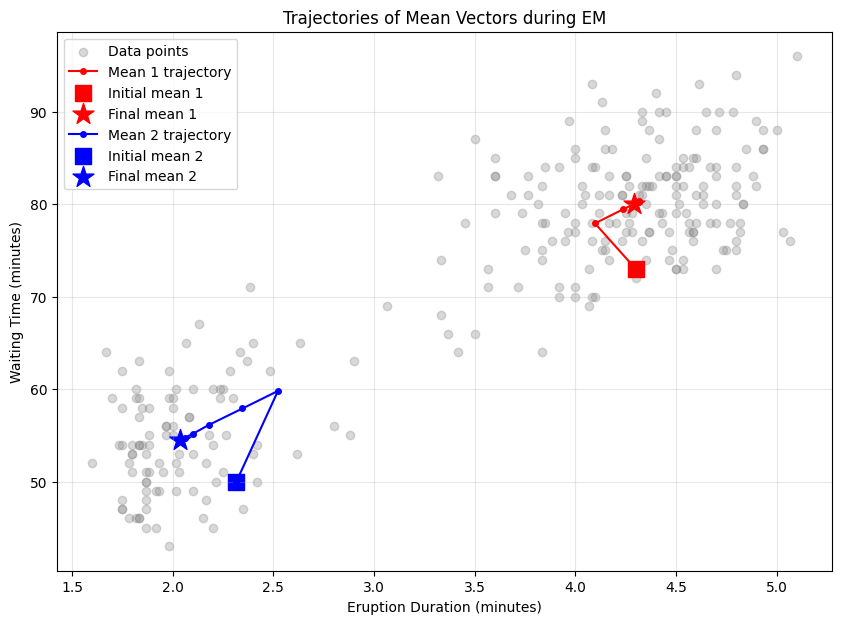

In [13]:
plt.figure(figsize=(10, 7))

# Original data points
plt.scatter(X[:, 0], X[:, 1],
            color='gray', alpha=0.3, label='Data points')

colors = ['red', 'blue']

for k in range(K):

    # Mean trajectory
    plt.plot(mu_history[:, k, 0],
             mu_history[:, k, 1],
             color=colors[k],
             marker='o',
             markersize=4,
             label=f'Mean {k+1} trajectory')

    # Initial mean
    plt.scatter(mu_history[0, k, 0],
                mu_history[0, k, 1],
                color=colors[k],
                marker='s', s=120,
                label=f'Initial mean {k+1}')

    # Final mean
    plt.scatter(mu_history[-1, k, 0],
                mu_history[-1, k, 1],
                color=colors[k],
                marker='*', s=250,
                label=f'Final mean {k+1}')

plt.xlabel('Eruption Duration (minutes)')
plt.ylabel('Waiting Time (minutes)')
plt.title('Trajectories of Mean Vectors during EM')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [14]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X)
kmeans_mu = kmeans.cluster_centers_

print("K-means cluster centers:\n", kmeans_mu)
print("\nEM cluster centers:\n", mu)

K-means cluster centers:
 [[ 4.29793023 80.28488372]
 [ 2.09433    54.75      ]]

EM cluster centers:
 [[ 4.2896645  79.96814579]
 [ 2.03639132 54.47854512]]


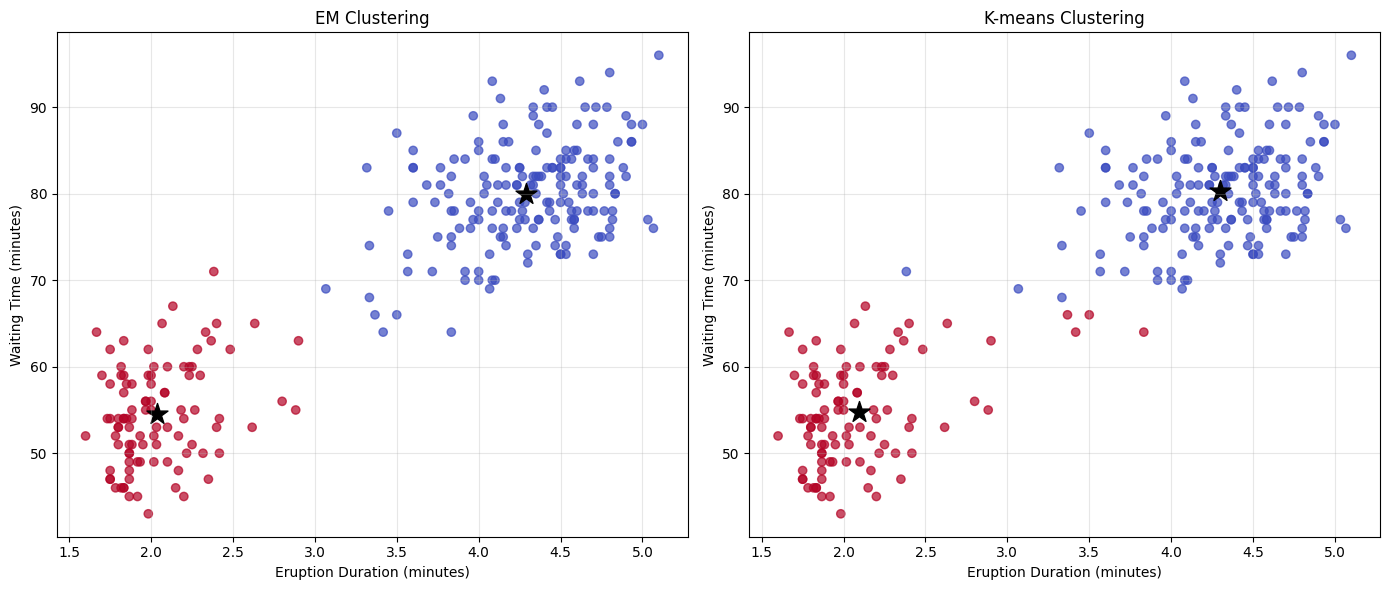

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# EM clustering
axes[0].scatter(X[:, 0], X[:, 1], c=labels,
                cmap='coolwarm', alpha=0.7)

axes[0].scatter(mu[:, 0], mu[:, 1],
                color='black', marker='*', s=250)

axes[0].set_title('EM Clustering')

# K-means clustering
axes[1].scatter(X[:, 0], X[:, 1], c=kmeans_labels,
                cmap='coolwarm', alpha=0.7)

axes[1].scatter(kmeans_mu[:, 0], kmeans_mu[:, 1],
                color='black', marker='*', s=250)

axes[1].set_title('K-means Clustering')

for ax in axes:
    ax.set_xlabel('Eruption Duration (minutes)')
    ax.set_ylabel('Waiting Time (minutes)')
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
if np.mean(labels == kmeans_labels) < 0.5:
    kmeans_labels = 1 - kmeans_labels

different = np.sum(labels != kmeans_labels)
agreement = np.mean(labels == kmeans_labels) * 100

print("Total observations:", len(X))
print("Differently assigned points:", different)
print(f"Clustering agreement: {agreement:.2f}%")

Total observations: 272
Differently assigned points: 5
Clustering agreement: 98.16%
